# 02 - Demand Forecasting
Six forecasters per series, compared with **rolling-origin cross-validation** (no leakage), automatic
best-model selection, empirical prediction intervals and SHAP.

| Model | Idea |
|---|---|
| Naive / Seasonal naive (7 d) | Baselines: last value / same weekday last week |
| SARIMAX | SARIMA(1,0,1)(1,1,1)7 + annual Fourier terms |
| Prophet | Trend + weekly + yearly seasonality + festive dates |
| XGBoost / LightGBM | Gradient-boosted trees on calendar, lag and rolling features (recursive multi-step) |

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src.config import load_config, results_dir

cfg = load_config()
RES, FIG = results_dir(cfg), ROOT / cfg["paths"]["figures_dir"]
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
pd.options.display.float_format = "{:,.2f}".format
def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=150); plt.show()

## 1. Features and leakage control
Every lag/rolling feature at day *t* uses only data up to *t-1*.

In [2]:
from src.data.store import read_daily
from src.features.engineering import build_feature_frame

daily = read_daily(cfg)
y = daily[daily.category == "N02BE"].set_index("date")["units"].asfreq("D")
X = build_feature_frame(y, cfg)
print(X.shape); X.tail(3).T

(2106, 21)


date,2019-10-06,2019-10-07,2019-10-08
weekday,6.00,0.00,1.00
is_weekend,1.00,0.00,0.00
month,10.00,10.00,10.00
quarter,4.00,4.00,4.00
day_of_month,6.00,7.00,8.00
week_of_year,40.00,41.00,41.00
is_month_end,0.00,0.00,0.00
doy_sin,-1.00,-0.99,-0.99
doy_cos,0.09,0.10,0.12
is_holiday,0.00,0.00,0.00


In [3]:
# leakage test: changing today's value must not change today's features
y2 = y.copy(); y2.iloc[-1] += 1000
print("features identical:", build_feature_frame(y2, cfg).iloc[-1].equals(X.iloc[-1]))

features identical: True


## 2. Rolling-origin cross-validation
Expanding window; each fold refits on the past only and predicts the next 14 days. 26 contiguous folds = the final 364 days are out-of-sample.

In [4]:
from src.models.cv import rolling_origins

cv = cfg["forecasting"]["cv"]
o = rolling_origins(len(y), cv["horizon"], cv["step"], cv["n_folds"], cv["min_train_days"])
print("folds:", len(o), "| first origin:", y.index[o[0]-1].date(), "| last test day:", y.index[-1].date())

folds: 26 | first origin: 2018-10-09 | last test day: 2019-10-08


### Live demonstration on one series (fast models only)
The full six-model CV is produced by `make train`.

In [5]:
from src.models import metrics as M
from src.models.cv import run_cv

demo = run_cv("N02BE", y, cfg, models=["naive", "snaive", "xgboost", "lightgbm"])
pd.DataFrame({m: M.all_metrics(g.y, g.yhat) for m, g in demo.groupby("model")}).T

,mae,rmse,mape,smape
lightgbm,9.27,12.26,34.94,33.09
naive,12.84,18.16,44.35,45.92
snaive,11.78,15.71,43.10,41.97
xgboost,9.38,12.23,35.84,33.69


## 3. Results of the full cross-validation (`reports/results/cv_metrics.csv`)

In [6]:
mt = pd.read_csv(RES / "cv_metrics.csv")
mt.pivot(index="category", columns="model", values="mae").assign(best=lambda d: d.idxmin(axis=1))

model,lightgbm,naive,prophet,sarimax,snaive,xgboost,best
category,,,,,,,
M01AB,2.29,3.02,2.21,2.21,2.96,2.31,prophet
M01AE,1.70,2.24,1.68,1.67,2.21,1.70,sarimax
N02BA,1.72,2.28,1.53,1.52,2.11,1.74,sarimax
N02BE,9.27,12.84,9.87,9.52,11.78,9.38,lightgbm
N05B,3.46,4.83,3.50,3.25,4.54,3.65,sarimax
N05C,0.88,0.93,0.87,0.85,1.11,0.93,sarimax
R03,5.95,7.58,6.16,5.80,8.49,6.28,sarimax
R06,1.77,2.50,1.75,1.72,2.41,1.79,sarimax


In [7]:
mt.pivot(index="category", columns="model", values="rmse").assign(best=lambda d: d.idxmin(axis=1))

model,lightgbm,naive,prophet,sarimax,snaive,xgboost,best
category,,,,,,,
M01AB,2.95,3.85,2.84,2.84,3.83,2.97,sarimax
M01AE,2.18,2.90,2.18,2.14,2.83,2.16,sarimax
N02BA,2.16,2.97,2.03,2.00,2.71,2.20,sarimax
N02BE,12.26,18.16,13.12,12.50,15.71,12.23,xgboost
N05B,4.32,6.19,4.38,4.14,5.83,4.51,sarimax
N05C,1.15,1.47,1.14,1.14,1.67,1.18,sarimax
R03,8.28,11.01,8.22,8.14,11.58,8.54,sarimax
R06,2.31,3.26,2.29,2.29,3.24,2.31,sarimax


In [8]:
mt.pivot(index="category", columns="model", values="smape")

model,lightgbm,naive,prophet,sarimax,snaive,xgboost
category,,,,,,
M01AB,46.43,67.17,45.85,45.71,61.50,46.66
M01AE,48.91,67.76,48.59,48.41,64.91,49.20
N02BA,58.13,81.14,56.58,55.41,77.58,58.34
N02BE,33.09,45.92,34.57,33.68,41.97,33.69
N05B,44.01,59.43,44.14,41.91,57.91,45.33
N05C,154.31,96.09,156.30,158.00,108.95,152.52
R03,87.77,104.10,88.39,86.22,117.08,89.07
R06,63.42,86.45,61.38,61.95,81.79,62.97


In [9]:
best = pd.read_csv(RES / "best_models.csv")
best[["category", "model", "mae", "rmse", "smape", "mape", "mase", "mae_improv_pct", "rmse_improv_pct", "smape_improv_pct"]]

,category,model,mae,rmse,smape,mape,mase,mae_improv_pct,rmse_improv_pct,smape_improv_pct
0,M01AB,sarimax,2.21,2.84,45.71,67.02,0.77,25.14,25.93,25.67
1,M01AE,sarimax,1.67,2.14,48.41,105.79,0.75,24.42,24.54,25.42
2,N02BA,sarimax,1.52,2.00,55.41,96.89,0.60,27.69,26.14,28.58
3,N02BE,xgboost,9.38,12.23,33.69,35.84,0.80,20.33,22.19,19.72
4,N05B,sarimax,3.25,4.14,41.91,57.65,0.62,28.38,28.96,27.63
5,N05C,sarimax,0.85,1.14,158.00,59.92,1.04,23.06,31.47,-45.02
6,R03,sarimax,5.80,8.14,86.22,123.40,1.08,31.66,29.72,26.35
7,R06,sarimax,1.72,2.29,61.95,59.27,0.85,28.90,29.41,24.26


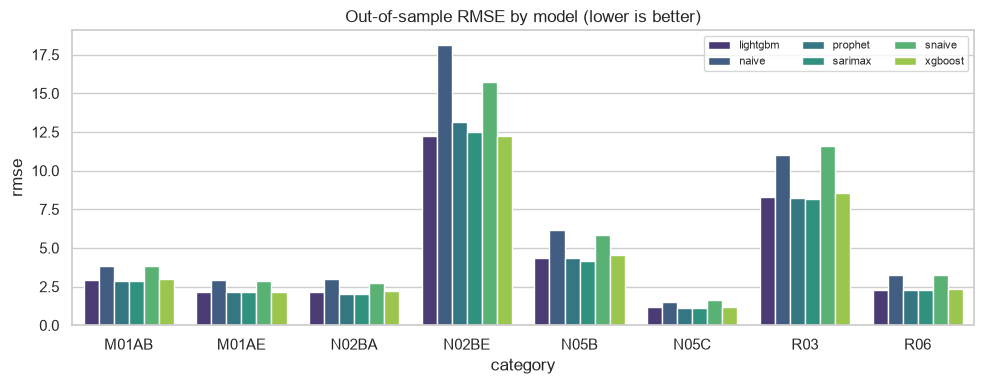

In [10]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(data=mt, x="category", y="rmse", hue="model", ax=ax, palette="viridis")
ax.set_title("Out-of-sample RMSE by model (lower is better)"); ax.legend(ncol=3, fontsize=8)
savefig("model_rmse_comparison")

### Error by forecast horizon

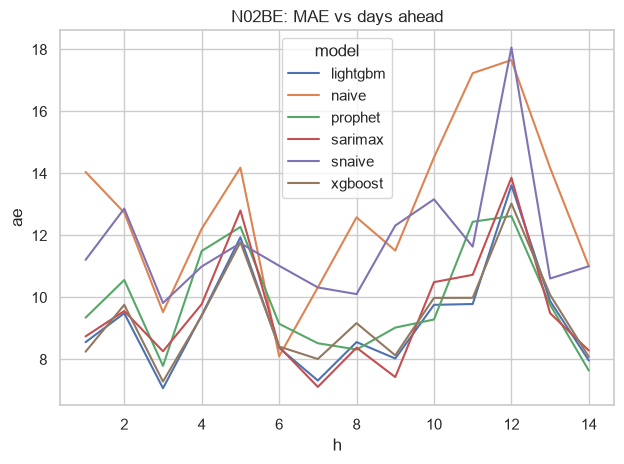

In [11]:
eh = pd.read_csv(RES / "cv_error_by_horizon.csv")
c = eh[eh.category == "N02BE"]
sns.lineplot(data=c, x="h", y="ae", hue="model"); plt.title("N02BE: MAE vs days ahead"); savefig("model_error_by_horizon")

### Out-of-sample forecasts of the selected model

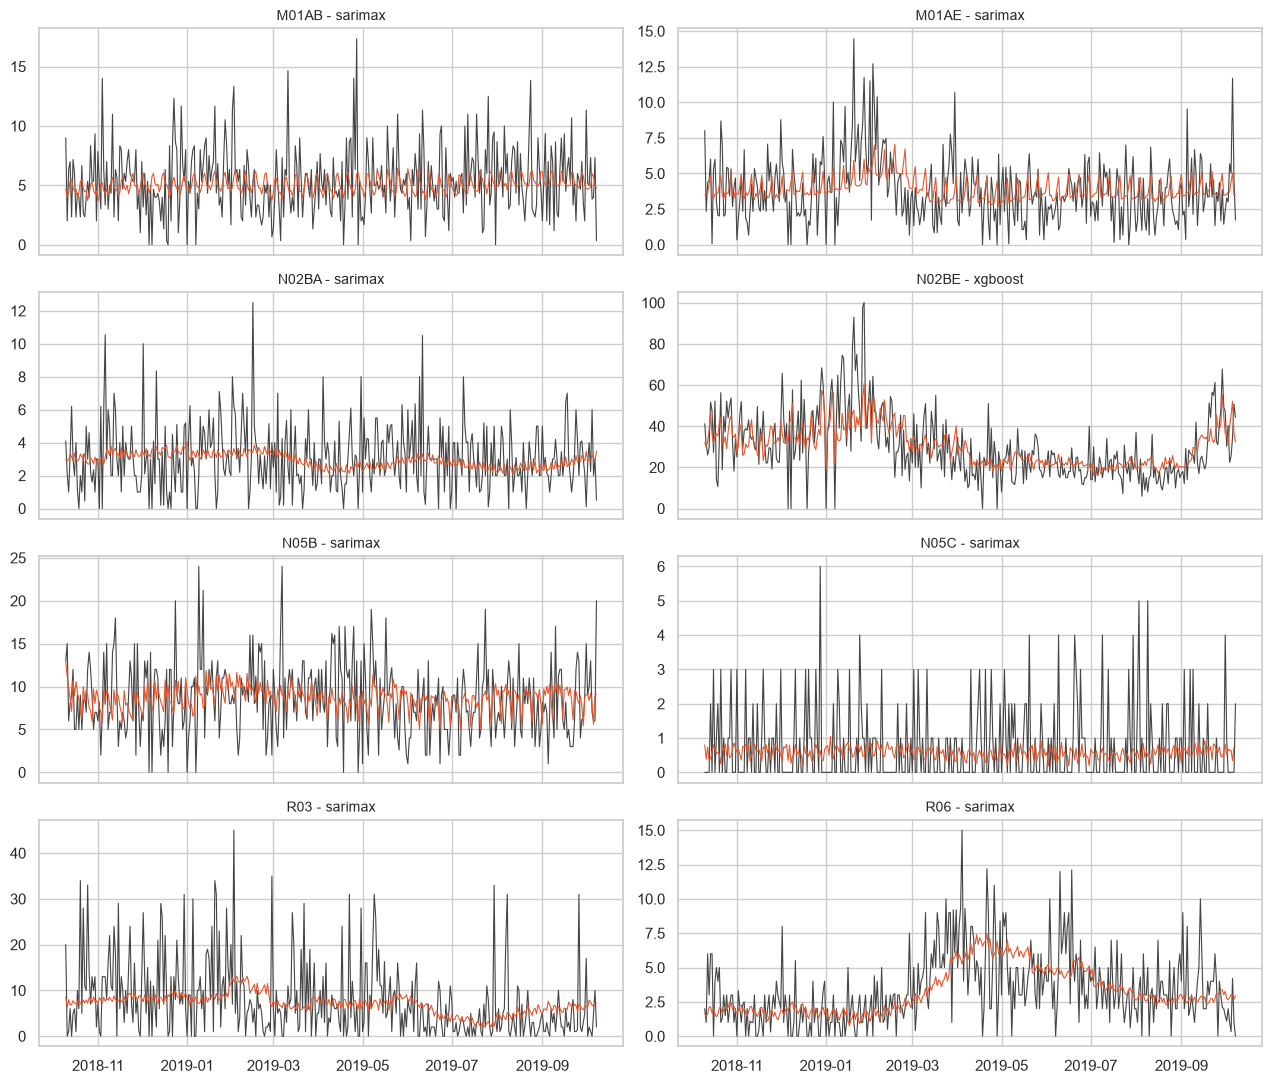

In [12]:
cvp = pd.read_parquet(RES / "cv_predictions.parquet")
bm = dict(zip(best.category, best.model))
fig, axes = plt.subplots(4, 2, figsize=(13, 11), sharex=True)
for ax, c in zip(axes.ravel(), sorted(bm)):
    g = cvp[(cvp.category == c) & (cvp.model == bm[c])].sort_values("date")
    ax.plot(g.date, g.y, lw=.8, color="#444"); ax.plot(g.date, g.yhat, lw=.8, color="#E4572E")
    ax.set_title(f"{c} - {bm[c]}", fontsize=10)
savefig("model_oos_forecasts")

## 4. Prediction intervals
Model-agnostic empirical intervals: residuals from several older forecast origins (up to 90 days ahead), scaled by sqrt(level) because count variance grows with the mean. Coverage is scored on the most recent origins after calibrating on older ones.

In [13]:
pd.read_csv(RES / "interval_coverage.csv")

,category,model,nominal,empirical_coverage
0,M01AB,sarimax,0.90,0.84
1,M01AE,sarimax,0.90,0.93
2,N02BA,sarimax,0.90,0.93
3,N02BE,xgboost,0.90,0.96
4,N05B,sarimax,0.90,0.93
5,N05C,sarimax,0.90,0.88
6,R03,sarimax,0.90,0.96
7,R06,sarimax,0.90,0.86


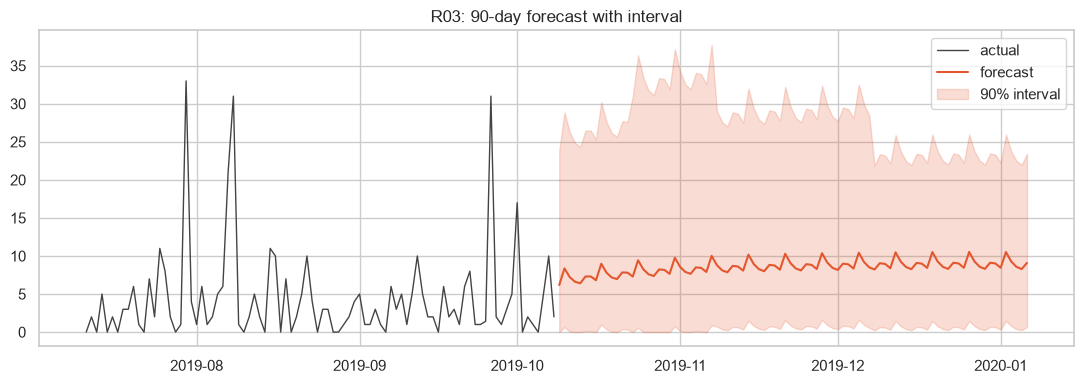

In [14]:
fb = pd.read_parquet(RES / "forecasts_best.parquet")
c = "R03"; g = fb[fb.category == c]; hist = daily[daily.category == c].set_index("date")["units"].iloc[-90:]
plt.figure(figsize=(11, 4)); plt.plot(hist.index, hist, color="#444", lw=1, label="actual")
plt.plot(g.date, g.yhat, color="#E4572E", label="forecast"); plt.fill_between(g.date, g.lower, g.upper, alpha=.2, color="#E4572E", label="90% interval")
plt.legend(); plt.title(f"{c}: 90-day forecast with interval"); savefig("model_forecast_interval")

## 5. Explainability: SHAP for the tree model

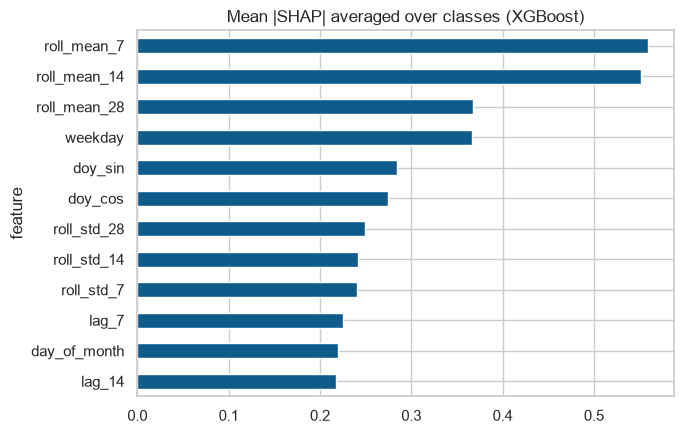

In [15]:
imp = pd.read_csv(RES / "shap_importance.csv")
top = imp.groupby("feature").mean_abs_shap.mean().sort_values().tail(12)
top.plot.barh(figsize=(7, 4.5), color="#0F5C8C", title="Mean |SHAP| averaged over classes (XGBoost)"); savefig("model_shap_global")

In [16]:
imp.pivot(index="feature", columns="category", values="mean_abs_shap").loc[top.index[::-1]]

category,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
feature,,,,,,,,
roll_mean_7,0.14,0.11,0.15,2.79,0.77,0.05,0.25,0.22
roll_mean_14,0.18,0.10,0.11,2.45,0.48,0.06,0.47,0.58
roll_mean_28,0.27,0.11,0.54,0.63,0.26,0.09,0.66,0.38
weekday,0.23,0.26,0.11,1.28,0.74,0.06,0.13,0.12
doy_sin,0.15,0.09,0.10,1.01,0.20,0.05,0.38,0.31
doy_cos,0.08,0.10,0.10,0.71,0.22,0.07,0.74,0.17
roll_std_28,0.12,0.12,0.10,0.68,0.40,0.10,0.40,0.07
roll_std_14,0.13,0.10,0.09,0.59,0.32,0.06,0.52,0.12
roll_std_7,0.15,0.08,0.11,0.72,0.23,0.03,0.49,0.11
